# 02 - Interpretabilite SHAP du Random Forest

En credit scoring, une decision de refus doit pouvoir etre justifiee. SHAP decompose chaque prediction en contributions des variables.

SHAP (`TreeExplainer`) est applique au Random Forest non calibre : la calibration sigmoid est une transformation monotone, elle ne change ni le classement des clients ni le sens des contributions.

In [1]:
from pathlib import Path

# Le notebook s'execute depuis notebooks/ (Jupyter / VS Code) ou depuis la racine du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

import sys

import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

sys.path.insert(0, str(ROOT / "src"))
from train_rf import build_rf  # memes hyperparametres que le modele de l'API

## Entrainement (meme split que `train_rf.py`)

In [2]:
df = pd.read_csv(ROOT / "data" / "processed" / "german_credit_features.csv")
X = df.drop(columns=["Credit Risk"]).astype(float)
y = df["Credit Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = build_rf()
model.fit(X_train, y_train)
print(f"AUC test : {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f}")

AUC test : 0.770


## Valeurs SHAP

In [3]:
explainer = shap.TreeExplainer(model)
# Explication de la classe 1 (defaut)
shap_values = explainer(X_test)[:, :, 1]
shap_values.shape

(191, 22)

## Vue globale

Chaque point est un client : la position indique l'effet sur le risque de defaut, la couleur la valeur de la variable.

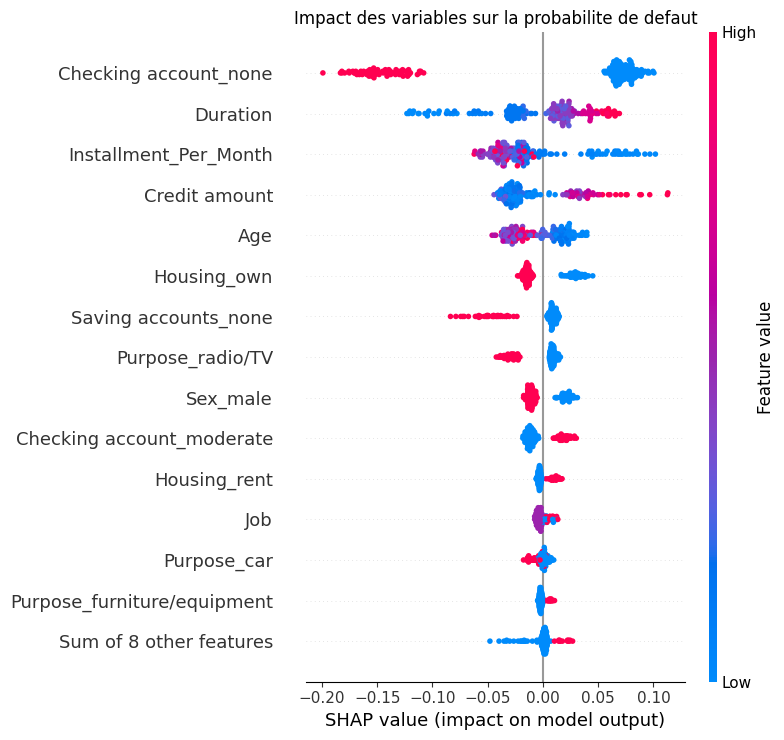

In [4]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("Impact des variables sur la probabilite de defaut")
plt.tight_layout()
plt.savefig(ROOT / "reports" / "shap_summary_plot.png", dpi=150, bbox_inches="tight")
plt.show()

## Explication individuelle : client le plus risque du jeu de test

Client 11 - probabilite de defaut (non calibree) : 0.739


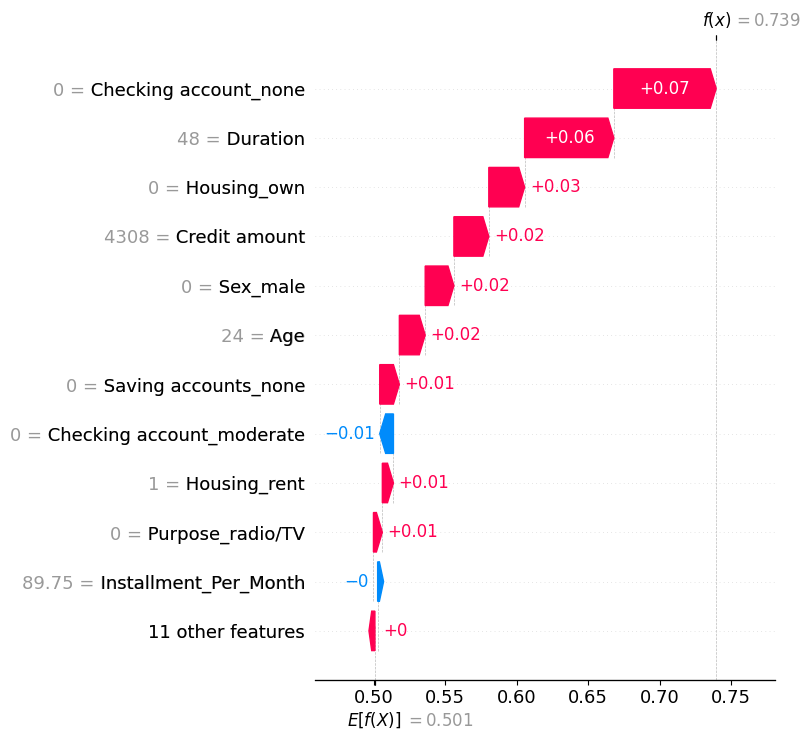

In [5]:
proba = model.predict_proba(X_test)[:, 1]
idx = proba.argmax()
print(f"Client {X_test.index[idx]} - probabilite de defaut (non calibree) : {proba[idx]:.3f}")

shap.plots.waterfall(shap_values[idx], max_display=12, show=False)
plt.tight_layout()
plt.savefig(ROOT / "reports" / "shap_waterfall_example.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions

- `Checking account_none`, `Duration` et `Credit amount` dominent, comme dans les importances du Random Forest et de la regression logistique.
- L'absence de compte courant reduit le risque, alors que les credits longs et eleves l'augmentent.
- Le waterfall fournit une justification individuelle exploitable pour expliquer un refus.